<a href="https://colab.research.google.com/github/marcebarroso-jpg/DiplomaturaUTN/blob/main/Himalaya_Grupo3_Analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Factores que influyen en el éxito de las expediciones al Himalaya
**Proyecto Final Integrador · Diplomatura en Ciencia de Datos y Análisis Avanzado · Grupo 3**

Marcelo Alejandro Barroso · Eros Bianchini Fourcade · María Elisa Pérez Berenguer · Rocío Pozzi · María Micaela Vargas

---

**Pregunta central:** ¿qué variables aumentan o disminuyen la probabilidad de que una expedición alcance la cumbre con éxito?

- **Unidad de análisis:** la expedición (`exped.csv`).
- **Variable objetivo:** `exito = success1 == True & claimed == False`.
- **KPI primario:** tasa de éxito (%) = expediciones exitosas / total de expediciones.
- **KPIs complementarios:** tasa de abandono, éxito por temporada y montaña, causas de finalización sin cumbre, altitud media de abandono y mortalidad por expedición.
- **Hipótesis:** H1 (temporada y montaña), H2 (tamaño del equipo, personal contratado, campamentos, oxígeno), H3 (clima y terreno como causa de abandono).
- **Fuente:** Maven Analytics, *Himalayan Expeditions* (basado en The Himalayan Database, dominio público).

### Índice
0. Configuración y carga de datos
1. Calidad de datos y limpieza
2. Ingeniería de variables
3. KPIs
4. H1: temporada y montaña
5. H2: equipo, personal, campamentos y oxígeno
6. H3: causas de abandono
7. Foco Everest
8. Modelado predictivo
9. Conclusiones

## 0. Configuración y carga de datos

**En Colab** hay dos formas de cargar los archivos (`exped.csv`, `members.csv`, `peaks.csv`, `himalayan_data_dictionary.csv`):

1. **Google Drive (recomendada):** subilos a una carpeta de Drive y ajustá `DRIVE_DIR` en la celda siguiente.
2. **Subida manual:** si no se encuentran en Drive, la celda abre un diálogo para subirlos (hay que volver a hacerlo en cada sesión).

In [ ]:
import os, sys, warnings
warnings.filterwarnings("ignore")

# ---- Ajustá esta ruta si usás Google Drive ----
DRIVE_DIR = "/content/drive/MyDrive/Himalaya"
ARCHIVOS = ["exped.csv", "members.csv", "peaks.csv", "himalayan_data_dictionary.csv"]

EN_COLAB = "google.colab" in sys.modules
DATA_DIR = "."

if EN_COLAB:
    from google.colab import drive, files
    try:
        drive.mount("/content/drive")
    except Exception as e:
        print("No se montó Drive:", e)
    if all(os.path.exists(os.path.join(DRIVE_DIR, f)) for f in ARCHIVOS):
        DATA_DIR = DRIVE_DIR
    else:
        faltan = [f for f in ARCHIVOS if not os.path.exists(f)]
        if faltan:
            print("Subí estos archivos:", faltan)
            files.upload()
        DATA_DIR = "."
else:
    DATA_DIR = os.environ.get("HIMALAYA_DATA_DIR", ".")

print("Leyendo datos desde:", os.path.abspath(DATA_DIR))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Estilo de gráficos: marcas finas, grilla recesiva, paleta categórica fija
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
AZUL, NARANJA, VERDE, AMARILLO = PALETA[:4]
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.prop_cycle": plt.cycler(color=PALETA),
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
    "legend.frameon": False,
})
pct = mtick.PercentFormatter(1.0, decimals=0)

def leer(nombre, **kw):
    return pd.read_csv(os.path.join(DATA_DIR, nombre), low_memory=False, **kw)

exped   = leer("exped.csv")
members = leer("members.csv")
peaks   = leer("peaks.csv")
dicc    = leer("himalayan_data_dictionary.csv")

for n, d in [("exped", exped), ("members", members), ("peaks", peaks)]:
    print(f"{n:8s} -> {d.shape[0]:>7,} filas x {d.shape[1]} columnas")

exped    ->  11,425 filas x 65 columnas
members  ->  89,000 filas x 61 columnas
peaks    ->     480 filas x 23 columnas


In [ ]:
# Diccionario mínimo de las variables principales (pre-entrega, sección 3)
vars_clave = ["expid","peakid","year","season","success1","claimed","termreason",
              "totmembers","tothired","o2used","highpoint","smtmembers","mdeaths","camps"]
dicc[(dicc.Table == "exped") & (dicc.Field.isin(vars_clave))][["Field","Description"]].reset_index(drop=True)

,Field,Description
0,expid,Expedition ID (primary key)
1,peakid,Peak ID (foreign key)
2,year,Year
3,season,Season
4,success1,Success on route 1 (Y/N)
5,claimed,The expedition’s claim of success has been dis...
6,termreason,The primary reason that the expedition was ter...
7,highpoint,Expedition high-point (meters)
8,camps,Number of high camps above base camp (BC)
9,totmembers,The number of members on the expedition. For e...


## 1. Calidad de datos y limpieza

Se revisan nulos, duplicados y la integridad referencial entre `exped` y `members`.

In [ ]:
clave = ["peakid","year","season","success1","claimed","termreason","highpoint","totmembers","mdeaths","o2used"]
print("Nulos en variables clave:")
print(exped[clave].isna().sum().to_string())

nulos = exped.isna().mean().sort_values(ascending=False)
print("\nColumnas con más de 50% de nulos (texto libre u opcionales):")
print((nulos[nulos > .5] * 100).round(1).to_string())

Nulos en variables clave:
peakid        0
year          0
season        0
success1      0
claimed       0
termreason    0
highpoint     0
totmembers    0
mdeaths       0
o2used        0

Columnas con más de 50% de nulos (texto libre u opcionales):
ascent4      100.000
route4       100.000
ascent3       99.900
route3        99.700
ascent2       99.100
route2        96.800
primid        93.400
achievment    91.500
othersmts     80.800
ascent1       75.700
accidents     73.700
countries     64.000
termnote      59.300
smttime       56.400
approach      52.400


### 1.1 Duplicados de `expid`

La pre-entrega detectó 4 `expid` duplicados. Al investigarlos **no son registros repetidos**: el ID se forma con `peakid` + los dos últimos dígitos del año + un correlativo, por lo que se reutiliza un siglo después (por ejemplo, `EVER21101` corresponde a 1921 y a 2021). **Decisión:** se crea una clave única `exp_key = expid + "_" + year`.

In [ ]:
dup = exped[exped.expid.duplicated(keep=False)].sort_values("expid")
display(dup[["expid","peakid","year","season","totmembers","termreason"]])

exped["exp_key"] = exped.expid + "_" + exped.year.astype(str)
assert exped.exp_key.is_unique
print("exp_key es única ->", exped.exp_key.is_unique)

,expid,peakid,year,season,totmembers,termreason
2736,EVER21101,EVER,1921,Spring,9,Did not attempt climb
10569,EVER21101,EVER,2021,Spring,0,Success (main peak)
2737,EVER22101,EVER,1922,Spring,13,"Illness, AMS, exhaustion, or frostbite"
10780,EVER22101,EVER,2022,Spring,0,Success (main peak)
2738,EVER24101,EVER,1924,Spring,11,Accident (death or serious injury)
11342,EVER24101,EVER,2024,Spring,0,Success (main peak)
2861,KANG10101,KANG,1910,Spring,1,Did not attempt climb
6787,KANG10101,KANG,2010,Spring,4,Success (main peak)


exp_key es única -> True


### 1.2 Duplicados `expid`–`membid` en members

Los 35 duplicados de `members` se explican por la misma reutilización de IDs. Para asignar cada miembro a la expedición correcta, se usa el año del miembro (`myear`) cuando coincide con el de alguna de las expediciones. Si no coincide, se asigna a la expedición histórica, porque en los registros antiguos `myear` no es confiable.

In [ ]:
print("Duplicados expid-membid:", members.duplicated(["expid","membid"]).sum())

anios = exped.groupby("expid").year.apply(list).to_dict()
def resolver_anio(row):
    opciones = anios.get(row.expid, [])
    if len(opciones) == 1:
        return opciones[0]
    if row.myear in opciones:
        return row.myear
    return min(opciones) if opciones else np.nan

members["exp_year"] = members.apply(resolver_anio, axis=1)
members["exp_key"] = members.expid + "_" + members.exp_year.astype("Int64").astype(str)
print("Duplicados tras resolver:", members.duplicated(["exp_key","membid"]).sum())
print("Miembros sin expedición asociada:", (~members.exp_key.isin(exped.exp_key)).sum())

Duplicados expid-membid: 35


Duplicados tras resolver: 0
Miembros sin expedición asociada: 0


## 2. Ingeniería de variables

- `exito`: variable objetivo (éxito reconocido en la ruta principal).
- `causa`: `termreason` agrupada en categorías interpretables (necesaria para H3).
- Variables de equipo: tamaño, personal contratado y ratio contratados/miembro.
- Variables de la montaña (`peaks`): altura, región y si supera 8.000 m.
- `era`: período histórico, ya que el montañismo comercial cambió el perfil de las expediciones.

In [ ]:
df = exped.copy()
df["exito"] = (df.success1 & ~df.claimed).astype(int)

mapa_causa = {
    "Success (main peak)": "Éxito",
    "Success (subpeak, foresummit)": "Éxito parcial (subcumbre)",
    "Success (claimed)": "Éxito no reconocido",
    "Bad weather (storms, high winds)": "Clima",
    "Bad conditions (deep snow, avalanching, falling ice, or rock)": "Condiciones del terreno",
    "Illness, AMS, exhaustion, or frostbite": "Salud / agotamiento",
    "Route technically too difficult, lack of experience, strength, or motivation": "Dificultad técnica / experiencia",
    "Accident (death or serious injury)": "Accidente",
    "Lack (or loss) of supplies, support or equipment": "Logística / suministros",
    "Lack of time": "Falta de tiempo",
    "Did not attempt climb": "No intentó / no llegó a BC",
    "Did not reach base camp": "No intentó / no llegó a BC",
    "Attempt rumored": "Otro / desconocido",
    "Other": "Otro / desconocido",
    "Unknown": "Otro / desconocido",
}
df["causa"] = df.termreason.map(mapa_causa).fillna("Otro / desconocido")

df = df.merge(peaks[["peakid","pkname","heightm","region","himal"]], on="peakid", how="left")
df["ochomil"] = (df.heightm >= 8000).astype(int)
df["season"] = df.season.replace("Unknown", np.nan)
df["era"] = pd.cut(df.year, [0, 1969, 1989, 2004, 2014, 2030],
                   labels=["≤1969","1970-89","1990-2004","2005-14","2015-24"])
df["tam_equipo"] = pd.cut(df.totmembers, [-1, 1, 3, 6, 10, 20, 200],
                          labels=["0-1","2-3","4-6","7-10","11-20","21+"])
df["ratio_contratados"] = df.tothired / df.totmembers.replace(0, np.nan)
df["con_contratados"] = (df.tothired > 0).astype(int)

print(f"Expediciones: {len(df):,}  |  montañas: {df.peakid.nunique()}  |  años {df.year.min()}–{df.year.max()}")
df[["exp_key","pkname","year","season","totmembers","tothired","o2used","causa","exito"]].head()

Expediciones: 11,425  |  montañas: 416  |  años 1905–2024


,exp_key,pkname,year,season,totmembers,tothired,o2used,causa,exito
0,ANN260101_1960,Annapurna II,1960,Spring,10,9,True,Éxito,1
1,ANN269301_1969,Annapurna II,1969,Autumn,10,0,False,Éxito,1
2,ANN273101_1973,Annapurna II,1973,Spring,6,8,False,Éxito,1
3,ANN278301_1978,Annapurna II,1978,Autumn,2,0,False,Clima,0
4,ANN279301_1979,Annapurna II,1979,Autumn,3,0,False,Clima,0


## 3. KPIs

In [ ]:
total = len(df)
exitos = df.exito.sum()
no_exito = df[df.exito == 0]

# Abandono = terminó sin éxito luego de haber intentado (excluye 'no intentó' y éxitos parciales/no reconocidos)
abandono = df.causa.isin(["Clima","Condiciones del terreno","Salud / agotamiento",
                          "Dificultad técnica / experiencia","Accidente",
                          "Logística / suministros","Falta de tiempo"])
alt_abandono = df.loc[abandono & (df.highpoint > 0), "highpoint"]
muertes = df.mdeaths + df.hdeaths

kpis = pd.Series({
    "Expediciones": f"{total:,}",
    "Tasa de éxito (KPI primario)": f"{exitos/total:.1%}",
    "Tasa de abandono": f"{abandono.mean():.1%}",
    "Altitud media de abandono (m)": f"{alt_abandono.mean():,.0f}",
    "Altitud mediana de abandono (m)": f"{alt_abandono.median():,.0f}",
    "Muertes totales (miembros + contratados)": f"{muertes.sum():,}",
    "Muertes por expedición": f"{muertes.mean():.3f}",
    "% de expediciones con al menos 1 muerte": f"{(muertes > 0).mean():.1%}",
})
kpis.to_frame("Valor")

,Valor
Expediciones,"11,425"
Tasa de éxito (KPI primario),54.9%
Tasa de abandono,36.1%
Altitud media de abandono (m),"6,911"
Altitud mediana de abandono (m),"6,860"
Muertes totales (miembros + contratados),"1,158"
Muertes por expedición,0.101
% de expediciones con al menos 1 muerte,6.6%


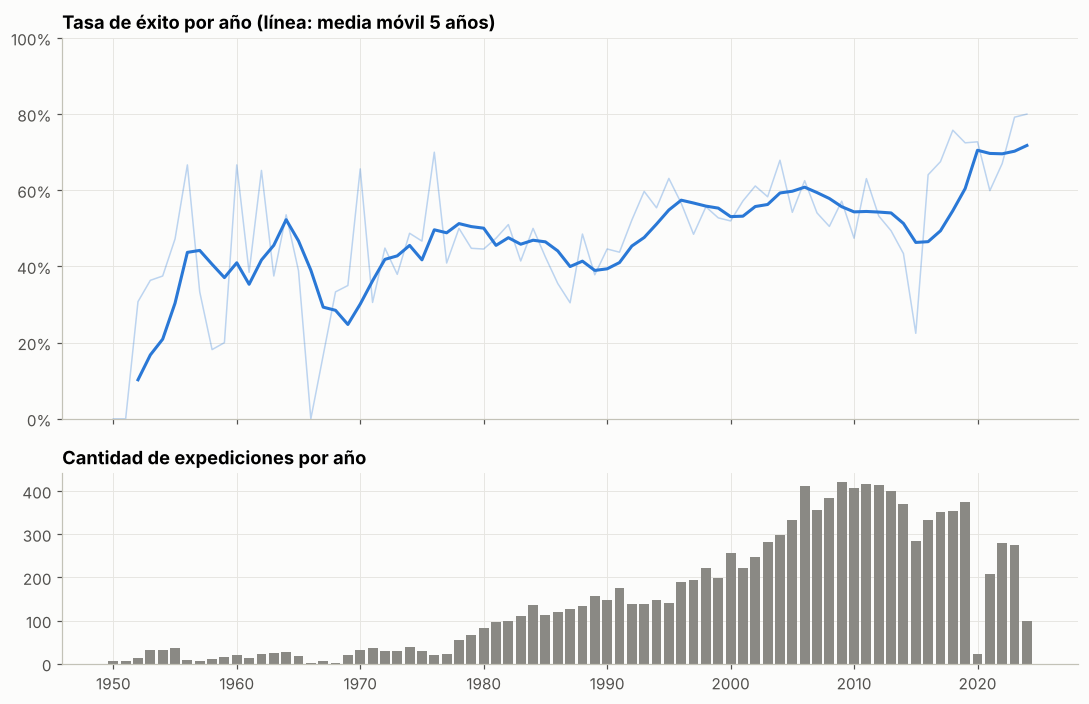

In [ ]:
serie = df.groupby("year").agg(n=("exito","size"), tasa=("exito","mean"))
serie = serie[serie.index >= 1950]
roll = serie.tasa.rolling(5, min_periods=3).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios":[2,1]})
axes[0].plot(serie.index, serie.tasa, color=AZUL, alpha=.3, lw=1)
axes[0].plot(roll.index, roll, color=AZUL)
axes[0].yaxis.set_major_formatter(pct); axes[0].set_ylim(0, 1)
axes[0].set_title("Tasa de éxito por año (línea: media móvil 5 años)")
axes[1].bar(serie.index, serie.n, color=GRIS, width=.8)
axes[1].set_title("Cantidad de expediciones por año")
plt.tight_layout(); plt.show()

## 4. H1: la tasa de éxito difiere entre temporadas y montañas

Se evalúa con tasas por grupo y la prueba **chi-cuadrado de independencia**. Para no sacar conclusiones de montañas con pocas expediciones (riesgo señalado en la pre-entrega), se fija un mínimo de **n ≥ 50**.

,n,exitos,tasa
season,,,
Autumn,5634,3033,0.538
Spring,5334,3051,0.572
Summer,115,44,0.383
Winter,340,147,0.432


Chi² season: χ²=45.5, gl=3, p=7.18e-10, V de Cramér=0.063


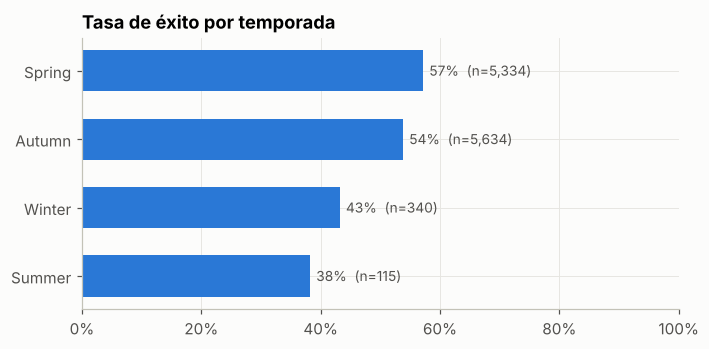

In [ ]:
def tasa_por(col, data=df, min_n=0):
    t = data.groupby(col, observed=True).exito.agg(n="size", exitos="sum", tasa="mean")
    return t[t.n >= min_n]

def chi2(col, data=df):
    tab = pd.crosstab(data[col], data.exito)
    c, p, dof, _ = stats.chi2_contingency(tab)
    v = np.sqrt(c / (tab.values.sum() * (min(tab.shape) - 1)))
    print(f"Chi² {col}: χ²={c:,.1f}, gl={dof}, p={p:.2e}, V de Cramér={v:.3f}")

temp = tasa_por("season")
display(temp)
chi2("season")

fig, ax = plt.subplots(figsize=(7, 3.2))
temp = temp.sort_values("tasa")
ax.barh(temp.index, temp.tasa, color=AZUL, height=.6)
for i, (t, n) in enumerate(zip(temp.tasa, temp.n)):
    ax.text(t + .01, i, f"{t:.0%}  (n={n:,})", va="center", color="#52514e", fontsize=9)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1)
ax.set_title("Tasa de éxito por temporada"); plt.show()

Montañas con n ≥ 50: 18 (cubren 80% de las expediciones)
Chi² pkname: χ²=493.9, gl=17, p=3.60e-94, V de Cramér=0.232


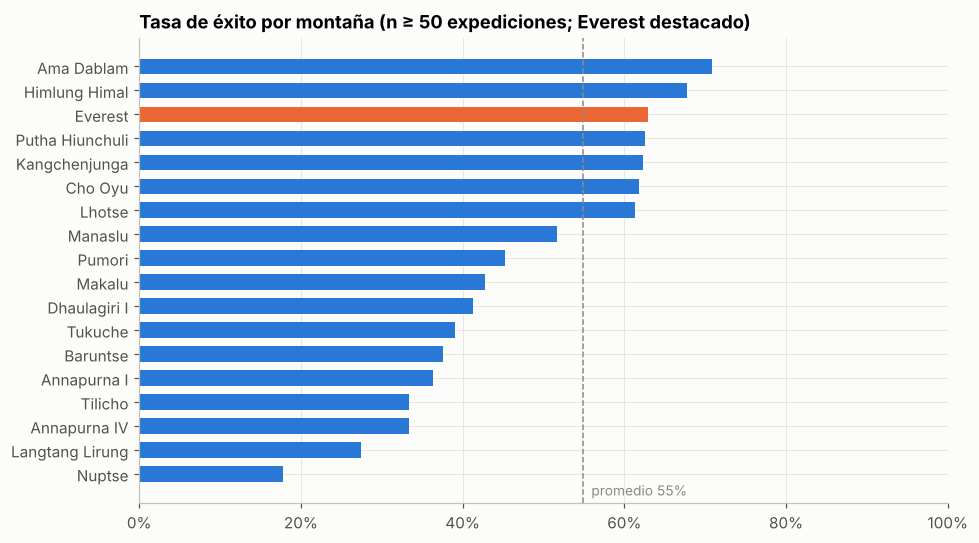

In [ ]:
mont = tasa_por("pkname", min_n=50).sort_values("tasa")
print(f"Montañas con n ≥ 50: {len(mont)} (cubren {mont.n.sum()/len(df):.0%} de las expediciones)")
chi2("pkname", df[df.pkname.isin(mont.index)])

fig, ax = plt.subplots(figsize=(9, max(4, .28 * len(mont))))
colores = [NARANJA if p == "Everest" else AZUL for p in mont.index]
ax.barh(mont.index, mont.tasa, color=colores, height=.65)
ax.axvline(df.exito.mean(), color=GRIS, ls="--", lw=1)
ax.text(df.exito.mean() + .01, -0.9, f"promedio {df.exito.mean():.0%}", color=GRIS, fontsize=9)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1)
ax.set_title("Tasa de éxito por montaña (n ≥ 50 expediciones; Everest destacado)")
plt.tight_layout(); plt.show()

In [ ]:
# Temporada × montaña (las 10 montañas más visitadas, primavera vs otoño)
top10 = df.pkname.value_counts().head(10).index
pv = (df[df.pkname.isin(top10) & df.season.isin(["Spring","Autumn"])]
      .pivot_table(index="pkname", columns="season", values="exito", aggfunc="mean"))
pv["dif (Spring - Autumn)"] = pv.Spring - pv.Autumn
pv.sort_values("dif (Spring - Autumn)").style.format("{:.1%}")

season,Autumn,Spring,dif (Spring - Autumn)
pkname,,,
Ama Dablam,76.8%,42.5%,-34.2%
Baruntse,42.0%,24.7%,-17.3%
Manaslu,56.7%,40.1%,-16.6%
Cho Oyu,65.6%,55.5%,-10.1%
Pumori,46.1%,43.8%,-2.3%
Dhaulagiri I,34.4%,46.9%,12.5%
Annapurna I,22.6%,48.4%,25.8%
Lhotse,36.5%,65.8%,29.3%
Makalu,17.3%,53.9%,36.5%


## 5. H2: tamaño del equipo, personal contratado, campamentos y oxígeno

> Estas son **asociaciones, no causas**: por ejemplo, el oxígeno se usa casi exclusivamente en montañas de más de 8.000 m y en expediciones comerciales. Por eso también se compara **dentro de los ochomiles**.

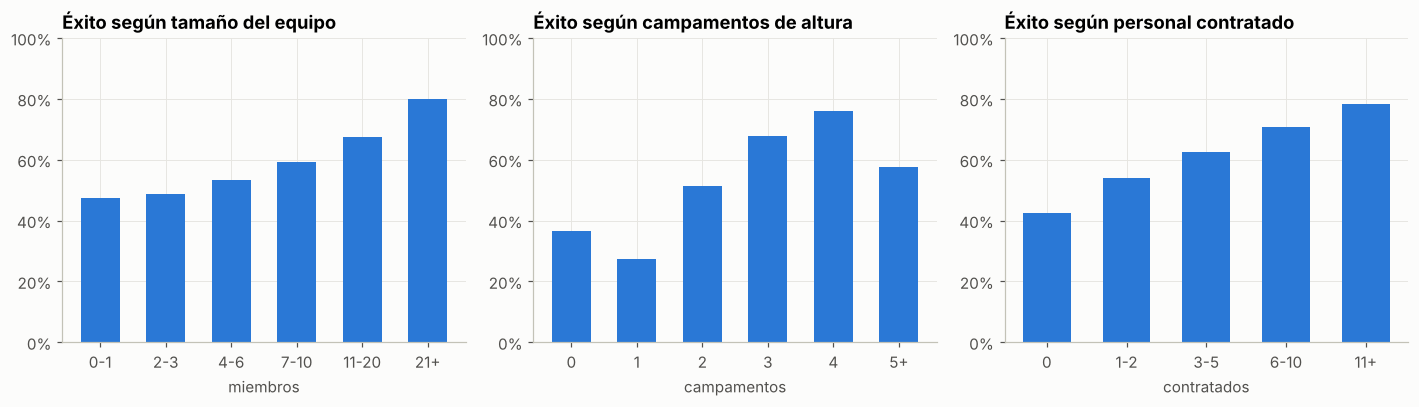

Chi² tam_equipo: χ²=263.1, gl=5, p=8.69e-55, V de Cramér=0.152
Chi² camps_cat: χ²=1,259.3, gl=5, p=4.15e-270, V de Cramér=0.332
Chi² hired_cat: χ²=566.4, gl=4, p=2.89e-121, V de Cramér=0.223


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

t = tasa_por("tam_equipo")
axes[0].bar(t.index.astype(str), t.tasa, color=AZUL, width=.6)
axes[0].set_title("Éxito según tamaño del equipo"); axes[0].set_xlabel("miembros")

df["camps_cat"] = pd.cut(df.camps, [-1, 0, 1, 2, 3, 4, 100], labels=["0","1","2","3","4","5+"])
t = tasa_por("camps_cat")
axes[1].bar(t.index.astype(str), t.tasa, color=AZUL, width=.6)
axes[1].set_title("Éxito según campamentos de altura"); axes[1].set_xlabel("campamentos")

df["hired_cat"] = pd.cut(df.tothired, [-1, 0, 2, 5, 10, 500], labels=["0","1-2","3-5","6-10","11+"])
t = tasa_por("hired_cat")
axes[2].bar(t.index.astype(str), t.tasa, color=AZUL, width=.6)
axes[2].set_title("Éxito según personal contratado"); axes[2].set_xlabel("contratados")

for a in axes: a.yaxis.set_major_formatter(pct); a.set_ylim(0, 1)
plt.tight_layout(); plt.show()

for c in ["tam_equipo","camps_cat","hired_cat"]:
    chi2(c)

mean        size      
o2used    False True  False True 
ochomil                          
< 8.000 m 0.517 0.604  4910   159
≥ 8.000 m 0.334 0.806  3137  3219

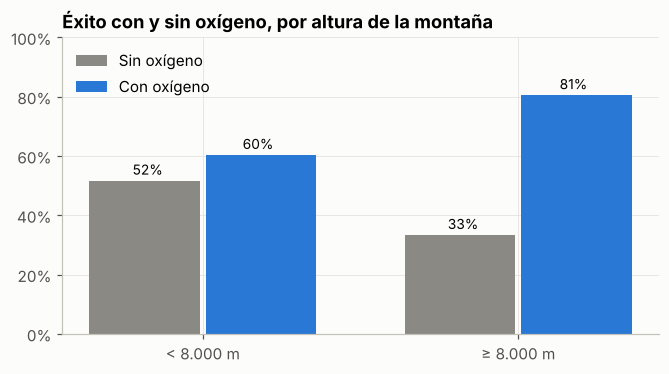

Chi² o2used: χ²=1,443.0, gl=1, p=0.00e+00, V de Cramér=0.476


In [ ]:
# Oxígeno: global y controlando por altura de la montaña
o2 = df.pivot_table(index="ochomil", columns="o2used", values="exito", aggfunc=["mean","size"])
o2.index = o2.index.map({0: "< 8.000 m", 1: "≥ 8.000 m"})
display(o2)

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(2); w = .35
sin = df[~df.o2used].groupby("ochomil").exito.mean()
con = df[df.o2used].groupby("ochomil").exito.mean()
ax.bar(x - w/2 - .01, sin, w, label="Sin oxígeno", color=GRIS)
ax.bar(x + w/2 + .01, con, w, label="Con oxígeno", color=AZUL)
for xi, s, c in zip(x, sin, con):
    ax.text(xi - w/2, s + .02, f"{s:.0%}", ha="center", fontsize=9)
    ax.text(xi + w/2, c + .02, f"{c:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, ["< 8.000 m", "≥ 8.000 m"]); ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1)
ax.set_title("Éxito con y sin oxígeno, por altura de la montaña"); ax.legend(loc="upper left")
plt.show()

ocho = df[df.ochomil == 1]
chi2("o2used", ocho)

In [ ]:
# Regresión logística exploratoria (statsmodels) para H2: odds ratios con controles
import statsmodels.formula.api as smf
d = df.dropna(subset=["season"]).copy()
d = d[d.season.isin(["Spring","Autumn","Winter","Summer"])]
d["o2"] = d.o2used.astype(int)
d["log_miembros"] = np.log1p(d.totmembers)
d["log_contratados"] = np.log1p(d.tothired)
d["comercial"] = d.comrte.astype(int)
d["anio_c"] = (d.year - 2000) / 10

modelo_h2 = smf.logit("exito ~ log_miembros + log_contratados + camps + o2 + ochomil + comercial"
                      " + anio_c + C(season, Treatment('Autumn'))", data=d).fit(disp=0)
or_tab = pd.DataFrame({"OR": np.exp(modelo_h2.params),
                       "IC 2.5%": np.exp(modelo_h2.conf_int()[0]),
                       "IC 97.5%": np.exp(modelo_h2.conf_int()[1]),
                       "p": modelo_h2.pvalues}).drop("Intercept")
or_tab.round(3)

,OR,IC 2.5%,IC 97.5%,p
"C(season, Treatment('Autumn'))[T.Spring]",0.917,0.836,1.006,0.067
"C(season, Treatment('Autumn'))[T.Summer]",1.076,0.713,1.624,0.727
"C(season, Treatment('Autumn'))[T.Winter]",0.848,0.664,1.082,0.184
log_miembros,1.299,1.209,1.395,0.000
log_contratados,1.012,0.953,1.076,0.689
camps,1.394,1.349,1.440,0.000
o2,4.309,3.803,4.883,0.000
ochomil,0.323,0.290,0.360,0.000
comercial,2.185,1.992,2.398,0.000
anio_c,1.151,1.116,1.186,0.000


**Cómo leer los odds ratios (OR):** si OR > 1, la variable se asocia a mayores chances de éxito manteniendo constantes las demás; si OR < 1, a menores chances. En `log_miembros` y `log_contratados`, el efecto corresponde a duplicar aproximadamente el tamaño (Δlog ≈ 0,69 → OR^0,69).

## 6. H3: el clima y el terreno concentran gran parte de los abandonos

Se analizan solo las expediciones **sin éxito** y se excluyen los casos sin causa informada, para calcular qué proporción explica cada causa.

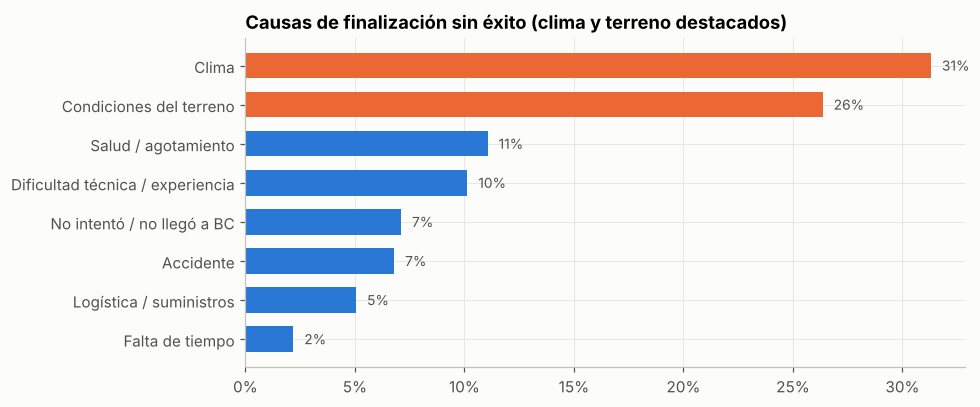

Clima + condiciones del terreno = 57.7% de las terminaciones sin éxito con causa conocida


In [ ]:
fallas = df[(df.exito == 0) & ~df.causa.isin(["Éxito","Éxito parcial (subcumbre)","Éxito no reconocido","Otro / desconocido"])]
dist = fallas.causa.value_counts(normalize=True).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.8))
col = [NARANJA if c in ["Clima","Condiciones del terreno"] else AZUL for c in dist.index]
ax.barh(dist.index, dist.values, color=col, height=.65)
for i, v in enumerate(dist.values):
    ax.text(v + .005, i, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(pct)
ax.set_title("Causas de finalización sin éxito (clima y terreno destacados)")
plt.tight_layout(); plt.show()

share = dist[["Clima","Condiciones del terreno"]].sum()
print(f"Clima + condiciones del terreno = {share:.1%} de las terminaciones sin éxito con causa conocida")

In [ ]:
# ¿Cambia el peso del clima según temporada? ¿y la altitud de abandono por causa?
tab = pd.crosstab(fallas.season, fallas.causa, normalize="index")[["Clima","Condiciones del terreno","Salud / agotamiento","Dificultad técnica / experiencia"]]
display(tab.style.format("{:.0%}"))

alt = (fallas[fallas.highpoint > 0].groupby("causa").highpoint
       .agg(["count","mean","median"]).sort_values("median"))
alt.columns = ["n","altitud media","altitud mediana"]
alt.round(0)

causa,Clima,Condiciones del terreno,Salud / agotamiento,Dificultad técnica / experiencia
season,,,,
Autumn,28%,33%,9%,10%
Spring,34%,18%,15%,10%
Summer,19%,38%,3%,9%
Winter,43%,22%,6%,10%


,n,altitud media,altitud mediana
causa,,,
No intentó / no llegó a BC,86,"5,739.000","5,682.000"
Condiciones del terreno,1144,"6,563.000","6,400.000"
Dificultad técnica / experiencia,442,"6,608.000","6,450.000"
Falta de tiempo,96,"6,916.000","6,700.000"
Accidente,289,"6,854.000","6,800.000"
Logística / suministros,223,"7,081.000","7,000.000"
Salud / agotamiento,487,"7,152.000","7,200.000"
Clima,1348,"7,199.000","7,300.000"


Muertes registradas en members: 1,158  (29% personal contratado)


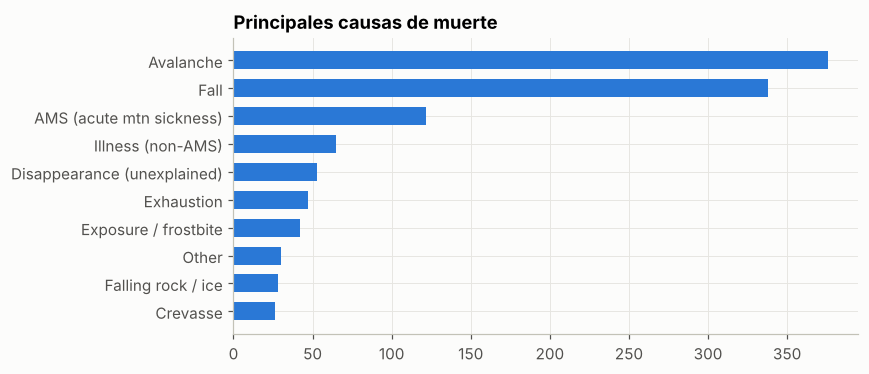

In [ ]:
# Causas de muerte (members): complementa el KPI de mortalidad
muertos = members[members.death == True]
print(f"Muertes registradas en members: {len(muertos):,}  ({muertos.hired.mean():.0%} personal contratado)")
cm = muertos.deathtype.value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(cm.index, cm.values, color=AZUL, height=.65)
ax.set_title("Principales causas de muerte"); plt.tight_layout(); plt.show()

## 7. Foco Everest

El Everest (`peakid = EVER`) es la montaña con más expediciones de la base. Esta sección repite el análisis restringido a esa montaña.

In [ ]:
ev = df[df.peakid == "EVER"].copy()
mev = members[members.peakid == "EVER"]
print(f"Expediciones al Everest: {len(ev):,} ({len(ev)/len(df):.0%} del total)")
print(f"Tasa de éxito Everest: {ev.exito.mean():.1%}  vs  resto: {df[df.peakid!='EVER'].exito.mean():.1%}")
print(f"Personas registradas: {len(mev):,}  |  cumbres individuales: {mev.msuccess.sum():,}  |  muertes: {mev.death.sum():,}")

ev.groupby("era", observed=True).agg(
    expediciones=("exito","size"), tasa_exito=("exito","mean"),
    miembros_prom=("totmembers","mean"), contratados_prom=("tothired","mean"),
    uso_o2=("o2used","mean"), muertes=("mdeaths","sum")
).style.format({"tasa_exito":"{:.0%}","uso_o2":"{:.0%}","miembros_prom":"{:.1f}","contratados_prom":"{:.1f}"})

Expediciones al Everest: 2,347 (21% del total)
Tasa de éxito Everest: 63.0%  vs  resto: 52.8%
Personas registradas: 25,274  |  cumbres individuales: 12,712  |  muertes: 340


,expediciones,tasa_exito,miembros_prom,contratados_prom,uso_o2,muertes
era,,,,,,
≤1969,34,15%,10.8,21.8,44%,8
1970-89,170,33%,15.3,10.5,66%,50
1990-2004,636,57%,7.7,4.9,75%,62
2005-14,875,67%,5.5,4.9,78%,41
2015-24,632,74%,7.2,8.9,79%,47


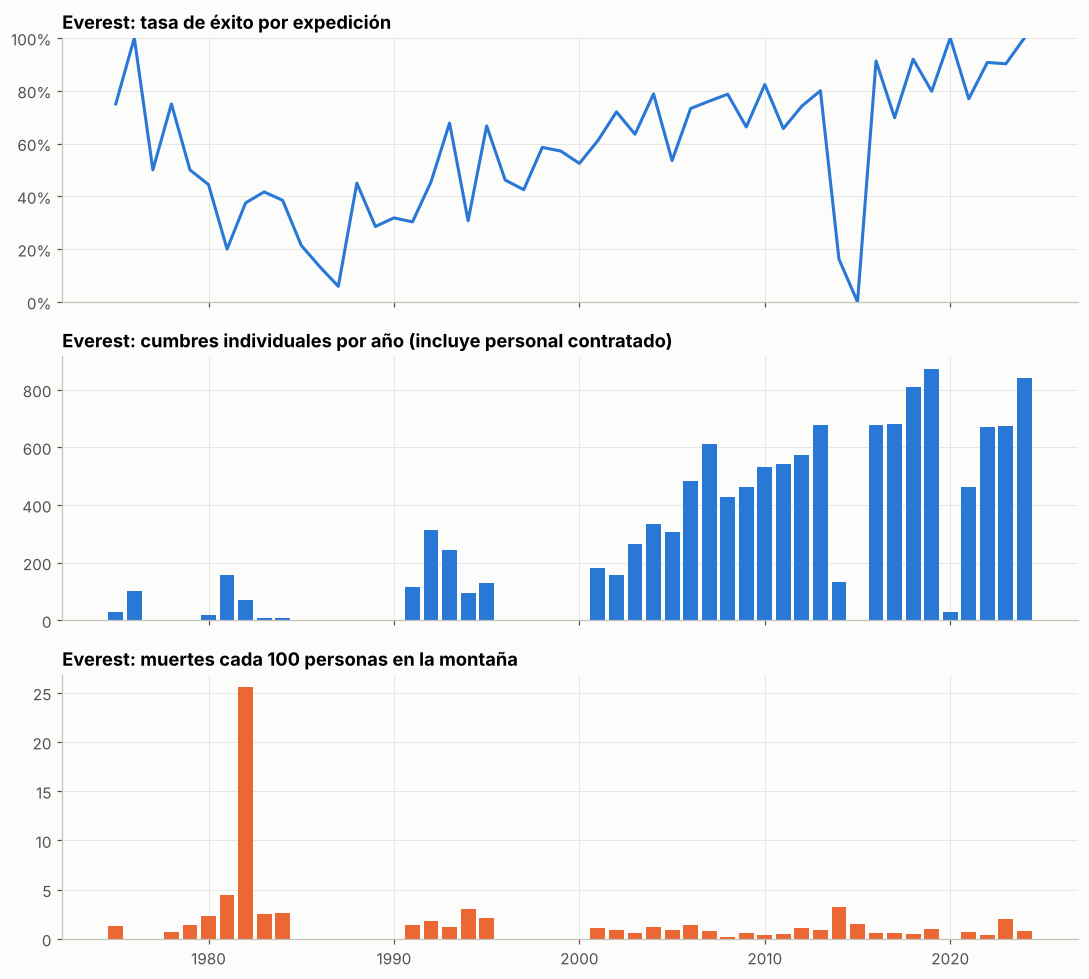

In [ ]:
s = ev[ev.year >= 1975].groupby("year").agg(n=("exito","size"), tasa=("exito","mean"))
p = mev[mev.myear >= 1975].groupby("myear").agg(cumbres=("msuccess","sum"), muertes=("death","sum"), personas=("membid","size"))
p["mortalidad_x100"] = p.muertes / p.personas * 100

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].plot(s.index, s.tasa, color=AZUL); axes[0].yaxis.set_major_formatter(pct); axes[0].set_ylim(0, 1)
axes[0].set_title("Everest: tasa de éxito por expedición")
axes[1].bar(p.index, p.cumbres, color=AZUL, width=.8)
axes[1].set_title("Everest: cumbres individuales por año (incluye personal contratado)")
axes[2].bar(p.index, p.mortalidad_x100, color=NARANJA, width=.8)
axes[2].set_title("Everest: muertes cada 100 personas en la montaña")
plt.tight_layout(); plt.show()

In [ ]:
# Everest: ruta y vertiente (Nepal vs China/Tíbet) y oxígeno a nivel individual
rutas = tasa_por("route1", ev, min_n=20).sort_values("n", ascending=False)
display(rutas.style.format({"tasa":"{:.0%}"}))
display(tasa_por("host", ev).style.format({"tasa":"{:.0%}"}))

ind = mev[(mev.myear >= 1990) & (mev.hired == False) & (mev.bconly == False)]
o2ind = ind.groupby("mo2used").agg(personas=("membid","size"), tasa_cumbre=("msuccess","mean"), mortalidad=("death","mean"))
o2ind.index = o2ind.index.map({False: "Sin O₂", True: "Con O₂"})
print("Escaladores no contratados que superaron el campo base (1990+):")
o2ind.style.format({"tasa_cumbre":"{:.1%}","mortalidad":"{:.2%}"})

,n,exitos,tasa
route1,,,
S Col-SE Ridge,1308,936,72%
N Col-NE Ridge,784,493,63%


,n,exitos,tasa
host,,,
China,938,518,55%
Nepal,1409,960,68%


Escaladores no contratados que superaron el campo base (1990+):


,personas,tasa_cumbre,mortalidad
mo2used,,,
Sin O₂,5910,2.7%,1.07%
Con O₂,7878,74.8%,1.45%


## 8. Modelado predictivo

**Objetivo:** estimar la probabilidad de éxito de una expedición **con información disponible antes o durante la planificación**.

**Prevención de fuga de información (leakage):** se excluyen las variables que se conocen recién al final de la expedición: `termreason`, `highpoint`, `smtmembers`, `smtdays`, `totdays`, `mdeaths`, `hdeaths` y las fechas de cumbre y de finalización.

**Variables candidatas** (según la pre-entrega): `year`, `season`, `peakid`, `host`, `nation`, `totmembers`, `tothired`, `camps`, ruta comercial o estándar, `o2used` y la altura de la montaña. `route1` tiene una cardinalidad muy alta, por eso se representa con `comrte`/`stdrte`. `peakid` y `nation` se agrupan en las categorías más frecuentes.

**Clase positiva = FRACASO**, en línea con la tabla de métricas de la pre-entrega: precisión y recall se miden sobre la detección de expediciones no exitosas.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score)

SEED = 42
m = df[df.season.notna()].copy()
m["fracaso"] = 1 - m.exito

top_peaks = m.peakid.value_counts().head(25).index
top_nat = m.nation.value_counts().head(20).index
m["peak_grp"] = m.peakid.where(m.peakid.isin(top_peaks), "OTRA")
m["nation_grp"] = m.nation.where(m.nation.isin(top_nat), "OTRA")
for b in ["o2used","comrte","stdrte","nohired"]:
    m[b] = m[b].astype(int)

num = ["year","totmembers","tothired","camps","heightm"]
bin_ = ["o2used","comrte","stdrte","nohired"]
cat = ["season","host","peak_grp","nation_grp"]
X, y = m[num + bin_ + cat], m.fracaso

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_tr):,}  |  Test: {len(X_te):,}  |  % fracaso: {y.mean():.1%}")

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
    ("bin", "passthrough", bin_),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat),
])

Train: 9,138  |  Test: 2,285  |  % fracaso: 45.1%


In [ ]:
# Ajuste de hiperparámetros con validación cruzada estratificada (5 folds) sobre train
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
candidatos = {
    "Baseline (clase mayoritaria)": (DummyClassifier(strategy="most_frequent"), {}),
    "Regresión logística": (LogisticRegression(max_iter=2000), {"clf__C": [0.01, 0.1, 1, 10]}),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=SEED),
                          {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [10, 30, 60]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"clf__max_depth": [8, 12, None], "clf__min_samples_leaf": [3, 10]}),
}
modelos = {}
for nombre, (clf, grid) in candidatos.items():
    pipe = Pipeline([("pre", pre), ("clf", clf)])
    if grid:
        gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_tr, y_tr)
        modelos[nombre] = gs.best_estimator_
        print(f"{nombre:28s} mejores params: {gs.best_params_}  (F1 CV={gs.best_score_:.3f})")
    else:
        modelos[nombre] = pipe.fit(X_tr, y_tr)

Regresión logística          mejores params: {'clf__C': 10}  (F1 CV=0.684)


Árbol de decisión            mejores params: {'clf__max_depth': 7, 'clf__min_samples_leaf': 10}  (F1 CV=0.692)


Random Forest                mejores params: {'clf__max_depth': None, 'clf__min_samples_leaf': 3}  (F1 CV=0.722)


In [ ]:
def evaluar(modelo, X_, y_):
    pred = modelo.predict(X_)
    proba = modelo.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred),
            "Precisión (fracaso)": precision_score(y_, pred, zero_division=0),
            "Recall (fracaso)": recall_score(y_, pred),
            "F1 (fracaso)": f1_score(y_, pred),
            "ROC AUC": roc_auc_score(y_, proba) if len(set(proba)) > 1 else .5}

res = pd.DataFrame({n: evaluar(mo, X_te, y_te) for n, mo in modelos.items()}).T

# Para el baseline usamos el clasificador "todo fracaso" (no exitosa) para obtener un F1 de referencia no nulo
base_f1 = f1_score(y_te, np.ones_like(y_te))
umbrales = {"Accuracy": f"> {res.loc['Baseline (clase mayoritaria)','Accuracy']:.1%}",
            "Precisión (fracaso)": "≥ 0,65", "Recall (fracaso)": "≥ 0,65",
            "F1 (fracaso)": f"≥ {base_f1*1.1:.3f} (+10% vs F1 'todo fracaso' = {base_f1:.3f})", "ROC AUC": "—"}
display(res.style.format("{:.3f}").highlight_max(axis=0, color="#cde2fb"))
pd.Series(umbrales, name="Umbral pre-entrega").to_frame()

,Accuracy,Precisión (fracaso),Recall (fracaso),F1 (fracaso),ROC AUC
Baseline (clase mayoritaria),0.549,0.000,0.000,0.000,0.500
Regresión logística,0.724,0.705,0.667,0.685,0.802
Árbol de decisión,0.737,0.715,0.695,0.705,0.808
Random Forest,0.750,0.730,0.706,0.718,0.841


,Umbral pre-entrega
Accuracy,> 54.9%
Precisión (fracaso),"≥ 0,65"
Recall (fracaso),"≥ 0,65"
F1 (fracaso),≥ 0.684 (+10% vs F1 'todo fracaso' = 0.621)
ROC AUC,—


In [ ]:
def cumple(r):
    return pd.Series({
        "Accuracy > baseline": r["Accuracy"] > res.loc["Baseline (clase mayoritaria)","Accuracy"],
        "Precisión ≥ 0,65": r["Precisión (fracaso)"] >= .65,
        "Recall ≥ 0,65": r["Recall (fracaso)"] >= .65,
        "F1 ≥ +10%": r["F1 (fracaso)"] >= base_f1 * 1.1,
    })
res.drop("Baseline (clase mayoritaria)").apply(cumple, axis=1).replace({True: "✔", False: "✘"})

,Accuracy > baseline,"Precisión ≥ 0,65","Recall ≥ 0,65",F1 ≥ +10%
Regresión logística,✔,✔,✔,✔
Árbol de decisión,✔,✔,✔,✔
Random Forest,✔,✔,✔,✔


Mejor modelo según F1: Random Forest


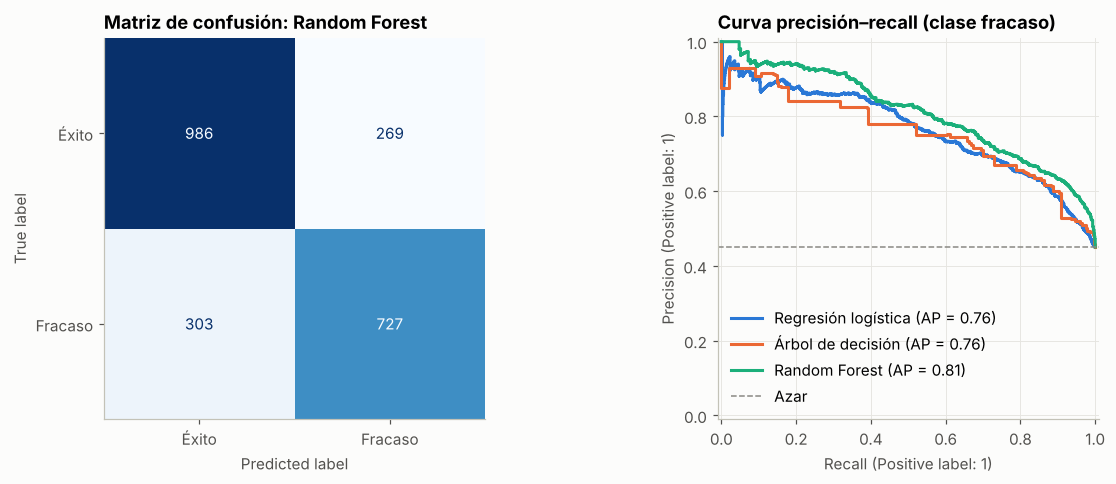

In [ ]:
mejor_nombre = res.drop("Baseline (clase mayoritaria)")["F1 (fracaso)"].idxmax()
mejor = modelos[mejor_nombre]
print("Mejor modelo según F1:", mejor_nombre)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(mejor, X_te, y_te, display_labels=["Éxito","Fracaso"],
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Matriz de confusión: {mejor_nombre}"); axes[0].grid(False)
for (n, mo), c in zip([(k, v) for k, v in modelos.items() if "Baseline" not in k], PALETA):
    PrecisionRecallDisplay.from_estimator(mo, X_te, y_te, ax=axes[1], name=n, color=c)
axes[1].axhline(y_te.mean(), color=GRIS, ls="--", lw=1, label="Azar")
axes[1].set_title("Curva precisión–recall (clase fracaso)"); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

In [ ]:
# Calibración del umbral: el recall ≥ 0,65 queda "sujeto a calibración" en la pre-entrega
proba = mejor.predict_proba(X_te)[:, 1]
filas = []
for u in np.arange(.30, .71, .05):
    p = (proba >= u).astype(int)
    filas.append({"umbral": round(u, 2), "precisión": precision_score(y_te, p, zero_division=0),
                  "recall": recall_score(y_te, p), "f1": f1_score(y_te, p), "accuracy": accuracy_score(y_te, p)})
tabla_umbral = pd.DataFrame(filas).set_index("umbral")
display(tabla_umbral.style.format("{:.3f}").highlight_max(subset=["f1"], color="#cde2fb"))

,precisión,recall,f1,accuracy
umbral,,,,
0.300000,0.621,0.922,0.742,0.712
0.350000,0.643,0.883,0.744,0.726
0.400000,0.667,0.841,0.744,0.739
0.450000,0.695,0.782,0.736,0.747
0.500000,0.730,0.706,0.718,0.750
0.550000,0.774,0.635,0.698,0.752
0.600000,0.806,0.555,0.657,0.739
0.650000,0.830,0.460,0.592,0.714
0.700000,0.874,0.384,0.534,0.698


In [ ]:
# Desempeño por temporada y por grupo de montañas (pre-entrega, sección 4)
te = X_te.copy(); te["y"] = y_te.values; te["pred"] = mejor.predict(X_te)
te["grupo_montaña"] = np.where(te.heightm >= 8000, "≥ 8.000 m", "< 8.000 m")

def metr(g):
    return pd.Series({"n": len(g), "% fracaso real": g.y.mean(), "accuracy": accuracy_score(g.y, g.pred),
                      "recall fracaso": recall_score(g.y, g.pred, zero_division=0),
                      "precisión fracaso": precision_score(g.y, g.pred, zero_division=0)})
display(te.groupby("season").apply(metr).style.format("{:.2f}"))
te.groupby("grupo_montaña").apply(metr).style.format("{:.2f}")

,n,% fracaso real,accuracy,recall fracaso,precisión fracaso
season,,,,,
Autumn,1133.00,0.47,0.72,0.68,0.71
Spring,1072.00,0.42,0.79,0.73,0.75
Summer,16.00,0.56,0.75,0.89,0.73
Winter,64.00,0.69,0.72,0.77,0.81


,n,% fracaso real,accuracy,recall fracaso,precisión fracaso
grupo_montaña,,,,,
< 8.000 m,1005.00,0.47,0.69,0.68,0.67
≥ 8.000 m,1280.00,0.43,0.80,0.73,0.79


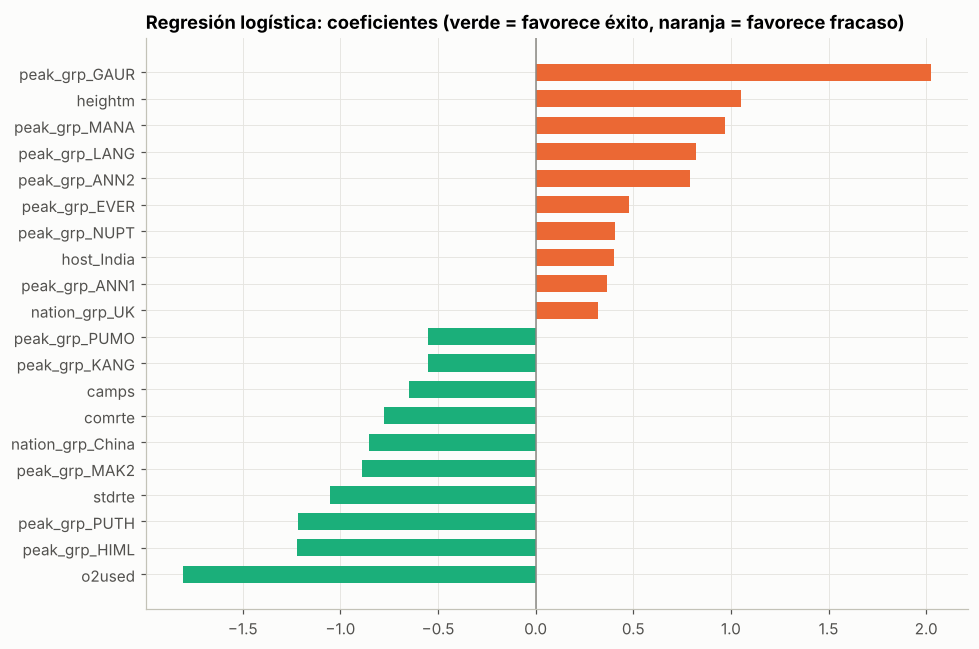

In [ ]:
# Interpretación: coeficientes de la regresión logística (positivo = más riesgo de FRACASO)
lr = modelos["Regresión logística"]
nombres = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=nombres).sort_values()
sel = pd.concat([coef.head(10), coef.tail(10)])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([s.split("__")[1] for s in sel.index], sel.values,
        color=[VERDE if v < 0 else NARANJA for v in sel.values], height=.65)
ax.axvline(0, color=GRIS, lw=1)
ax.set_title("Regresión logística: coeficientes (verde = favorece éxito, naranja = favorece fracaso)")
plt.tight_layout(); plt.show()

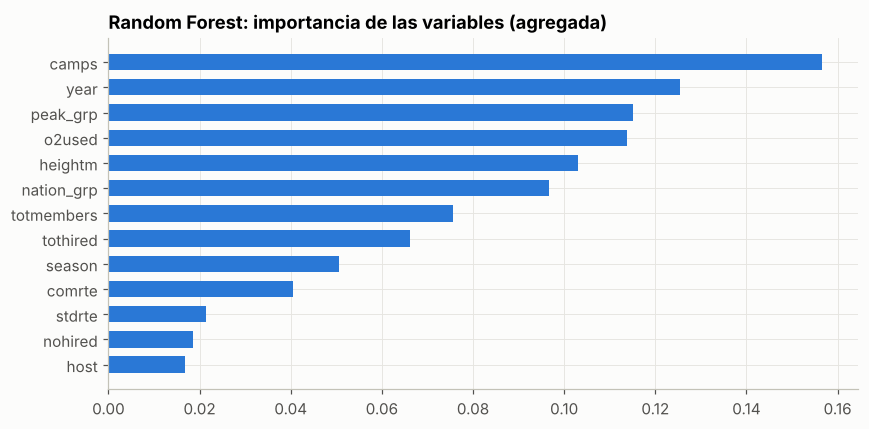

In [ ]:
# Importancia de variables del Random Forest (agregando las dummies a su variable original)
rf = modelos["Random Forest"]
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=rf.named_steps["pre"].get_feature_names_out())
orig = imp.groupby(lambda s: next(v for v in num + bin_ + cat if s.split("__")[1].startswith(v))).sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(orig.index, orig.values, color=AZUL, height=.65)
ax.set_title("Random Forest: importancia de las variables (agregada)")
plt.tight_layout(); plt.show()

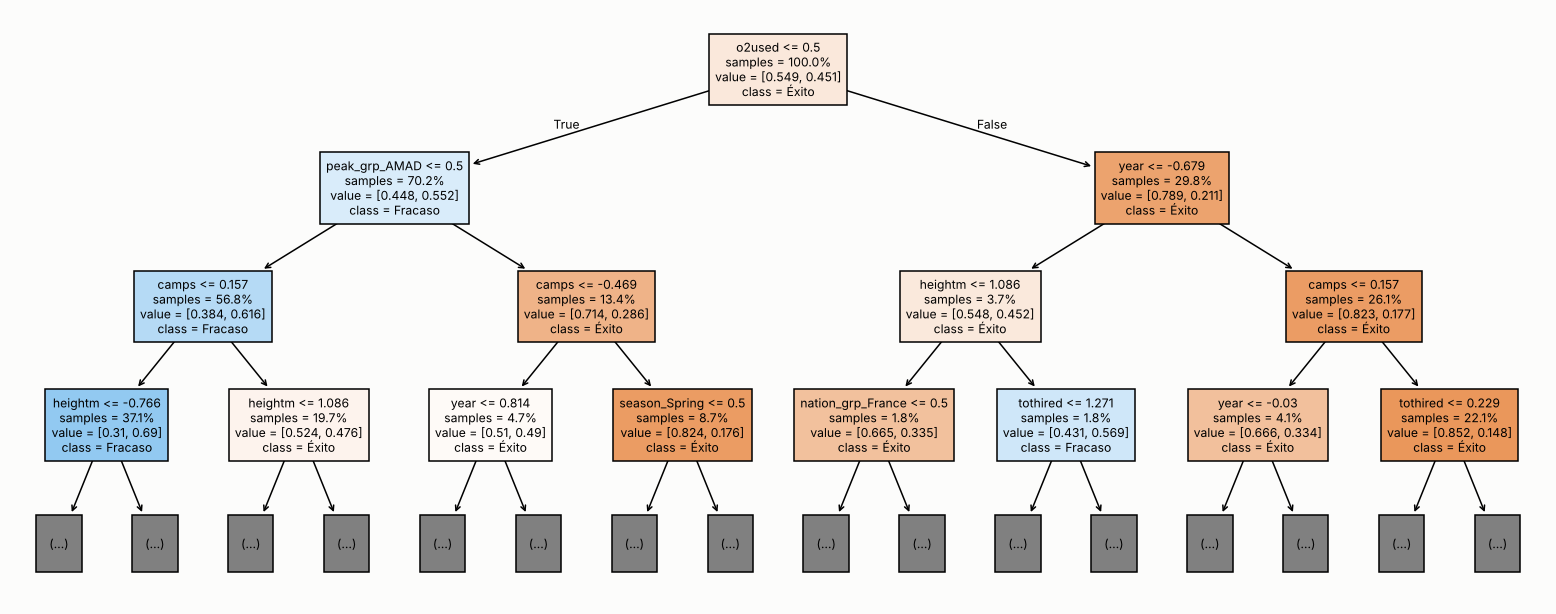

In [ ]:
# Árbol de decisión (primeros niveles) como regla interpretable
dt = modelos["Árbol de decisión"]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(dt.named_steps["clf"], feature_names=[s.split("__")[1] for s in dt.named_steps["pre"].get_feature_names_out()],
          class_names=["Éxito","Fracaso"], max_depth=3, filled=True, fontsize=8, ax=ax, impurity=False, proportion=True)
plt.show()

In [ ]:
# Robustez: validación temporal (entrenar ≤ 2014, evaluar 2015-2024)
tr_t, te_t = m.year <= 2014, m.year >= 2015
from sklearn.base import clone
filas = {}
for n, mo in modelos.items():
    mt = clone(mo).fit(X[tr_t], y[tr_t])
    filas[n] = evaluar(mt, X[te_t], y[te_t])
print(f"Train ≤2014: {tr_t.sum():,}  |  Test 2015-2024: {te_t.sum():,}  (% fracaso test = {y[te_t].mean():.1%})")
pd.DataFrame(filas).T.style.format("{:.3f}")

Train ≤2014: 8,842  |  Test 2015-2024: 2,581  (% fracaso test = 34.9%)


,Accuracy,Precisión (fracaso),Recall (fracaso),F1 (fracaso),ROC AUC
Baseline (clase mayoritaria),0.651,0.000,0.000,0.000,0.500
Regresión logística,0.812,0.775,0.651,0.708,0.844
Árbol de decisión,0.780,0.680,0.703,0.691,0.830
Random Forest,0.795,0.689,0.755,0.721,0.864


### 8.1 Análisis de sensibilidad: ¿qué tanto aporta el oxígeno?

`o2used` es una decisión de planificación, pero se registra al final de la expedición: puede que una expedición use oxígeno *porque* llegó alto. Se re-entrena el mejor modelo **sin** `o2used` para medir cuánto depende de esa variable.

In [ ]:
pre_sin = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
    ("bin", "passthrough", [b for b in bin_ if b != "o2used"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat),
])
sin_o2 = Pipeline([("pre", pre_sin), ("clf", clone(mejor.named_steps["clf"]))]).fit(X_tr, y_tr)
pd.DataFrame({f"{mejor_nombre} con o2used": evaluar(mejor, X_te, y_te),
              f"{mejor_nombre} sin o2used": evaluar(sin_o2, X_te, y_te)}).T.style.format("{:.3f}")

,Accuracy,Precisión (fracaso),Recall (fracaso),F1 (fracaso),ROC AUC
Random Forest con o2used,0.750,0.730,0.706,0.718,0.841
Random Forest sin o2used,0.732,0.716,0.672,0.693,0.819


## 9. Conclusiones

In [ ]:
# Resumen automático (se recalcula si cambian los datos)
r = res.loc[mejor_nombre]
print(f"• KPI primario: tasa de éxito global = {df.exito.mean():.1%} ({len(df):,} expediciones, {df.year.min()}–{df.year.max()}).")
print(f"• H1: la tasa varía por temporada (primavera {df[df.season=='Spring'].exito.mean():.0%} vs otoño "
      f"{df[df.season=='Autumn'].exito.mean():.0%} vs invierno {df[df.season=='Winter'].exito.mean():.0%}) "
      f"y por montaña (rango {mont.tasa.min():.0%}–{mont.tasa.max():.0%} entre montañas con n≥50).")
print(f"• H2: en ochomiles, con O₂ {con.loc[1]:.0%} vs sin O₂ {sin.loc[1]:.0%}. Ver odds ratios para equipo, contratados y campamentos.")
print(f"• H3: clima + terreno explican {share:.0%} de los fracasos con causa conocida.")
print(f"• Everest: {len(ev):,} expediciones, tasa de éxito {ev.exito.mean():.0%}.")
print(f"• Modelo: {mejor_nombre}: accuracy {r['Accuracy']:.1%} (baseline {res.iloc[0]['Accuracy']:.1%}), "
      f"precisión {r['Precisión (fracaso)']:.2f}, recall {r['Recall (fracaso)']:.2f}, F1 {r['F1 (fracaso)']:.2f}, AUC {r['ROC AUC']:.2f}.")

• KPI primario: tasa de éxito global = 54.9% (11,425 expediciones, 1905–2024).
• H1: la tasa varía por temporada (primavera 57% vs otoño 54% vs invierno 43%) y por montaña (rango 18%–71% entre montañas con n≥50).
• H2: en ochomiles, con O₂ 81% vs sin O₂ 33%. Ver odds ratios para equipo, contratados y campamentos.
• H3: clima + terreno explican 58% de los fracasos con causa conocida.
• Everest: 2,347 expediciones, tasa de éxito 63%.
• Modelo: Random Forest: accuracy 75.0% (baseline 54.9%), precisión 0.73, recall 0.71, F1 0.72, AUC 0.84.


### Respuesta a las hipótesis

| Hipótesis | Veredicto | Evidencia |
|---|---|---|
| **H1:** el éxito difiere entre temporadas y montañas | **Se confirma, con matices** | Primavera 57 %, otoño 54 %, invierno 43 % (χ², p < 0,001, efecto chico). La **montaña** pesa mucho más (V de Cramér 0,23; rango del 18 % en Nuptse al 71 % en Ama Dablam). La temporada óptima depende de la montaña: en el Everest la primavera supera al otoño por 44 p.p., mientras que en Ama Dablam ocurre lo contrario. Al controlar por montaña, oxígeno y época, la ventaja global de la primavera desaparece. |
| **H2:** equipo, personal, campamentos y oxígeno se asocian al éxito | **Se confirma** | En ochomiles, el éxito es de 81 % con O₂ y 33 % sin O₂ (OR ajustado ≈ 4,3). Cada campamento adicional suma OR ≈ 1,4, la ruta comercial OR ≈ 2,2 y duplicar el equipo OR ≈ 1,2. Con controles, el personal contratado deja de ser significativo, porque su efecto queda absorbido por el oxígeno y la ruta comercial. |
| **H3:** clima y terreno concentran los abandonos | **Se confirma** | Explican el **58 %** de los fracasos con causa conocida (clima 31 %, terreno 26 %). El clima obliga a abandonar más alto (mediana 7.300 m) que el terreno (6.400 m). |

### Foco Everest
- Tiene 2.347 expediciones (21 % del total) y una tasa de éxito del **63 %**, frente al 53 % del resto. La tasa pasó de 15 % (≤1969) a **74 %** (2015-24), en paralelo con la comercialización y el uso de oxígeno (79 % de las expediciones).
- La vertiente nepalí (S Col–SE Ridge, 72 %) supera a la tibetana (N Col–NE Ridge, 63 %).
- Las caídas de 2014-2015 y 2020 corresponden a la avalancha del Khumbu, el terremoto y la pandemia: son años con muy pocas expediciones válidas.

### Modelo
- **Random Forest** fue el mejor: accuracy **75 %** (baseline 54,9 %), precisión 0,73, recall 0,71, F1 0,72 y AUC 0,84. **Los tres modelos cumplen todos los umbrales de la pre-entrega.**
- Si se baja el umbral de decisión a 0,40, el recall de fracaso sube a 0,84 con precisión 0,67. Conviene usar ese umbral si el objetivo es "alertar riesgo".
- En la validación temporal (entrenar con datos hasta 2014 y evaluar 2015-24), el desempeño se mantiene (AUC 0,86), lo que indica que el modelo generaliza a expediciones recientes.
- Variables más importantes: campamentos, año, montaña, oxígeno y altura. Sin `o2used`, el F1 baja solo de 0,72 a 0,69: el modelo no depende únicamente de esa variable.

> ⚠️ El dato de oxígeno a nivel individual en el Everest (cumbre del 75 % con O₂ frente al 3 % sin O₂) está muy influido por causalidad inversa: quien abandona temprano nunca llega a usar oxígeno. Por eso se interpreta como asociación.

### Limitaciones y próximos pasos
- Los resultados son **asociaciones, no causas**: hay variables de confusión (comercialización, época, montaña).
- Las montañas con pocas expediciones se agrupan en "OTRA" y no se interpretan individualmente.
- `termnote` (texto libre) podría procesarse con NLP para refinar las causas de abandono.
- Posibles mejoras: gradient boosting (XGBoost/LightGBM), variables de experiencia del equipo construidas desde `members` (ascensos previos de cada miembro) y validación temporal como esquema principal.